# EcoFOCIpy RCM vs ADCP

Compare data using the ERDDAP hosted datasets for both instruments:
- 2D EIN/Vel datasets for the ADCP
- 1D dataset (at a specific depth) embedded in the mooring dataset


In [4]:
import pandas as pd
import xarray as xr
import numpy as np
import datetime
import EcoFOCIpy.io.erddap as erddap

url = "http://akutan.pmel.noaa.gov:8080/erddap"

erddap.test_erddap_connection(url=url) #basic test for connection to internal server, no response is a good thing

In [5]:
rcm_data = erddap.erddapMooredInstretrieve(url=url,mooringid='25bs8a',qclevel='final',instrid='25bs8a_an9_0064m')
rcm_data.columns = [x.split()[0] for x in rcm_data.columns]

In [6]:
rcm_data = rcm_data.set_index(pd.to_datetime(rcm_data['time'])).tz_localize(None).drop('time',axis=1)

In [9]:
# adcp_data = xr.load_dataset(url+'/griddap/ADCP_Mooring_25bsp8a_final')
adcp_data = xr.load_dataset('/Users/bell/ecoraid/2025/Moorings/25bsp8a/working/25bsp8a_wcp_velein.nc')


In [10]:
adcp_rcm_depth = adcp_data.sel(depth=(rcm_data['depth'].median()), method="nearest").to_dataframe().droplevel(['latitude','longitude'])

In [12]:
adcp_rcm_depth

,u_curr_comp,v_curr_comp,w_curr_comp,w_curr_comp_err,agc1,agc2,agc3,agc4,depth
time,,,,,,,,,
2025-08-15 03:00:00,-2.663194,-11.870442,-0.4,-0.9,141.0,139.0,147.0,142.0,52.0
2025-08-15 04:00:00,-8.864350,-4.514787,0.2,0.1,136.0,135.0,146.0,140.0,52.0
2025-08-15 05:00:00,-8.353728,1.065470,-0.3,-0.1,147.0,153.0,156.0,156.0,52.0
2025-08-15 06:00:00,-4.359418,9.857255,0.0,0.2,154.0,154.0,158.0,163.0,52.0
2025-08-15 07:00:00,3.750585,15.215226,0.0,-0.2,137.0,130.0,137.0,139.0,52.0
...,...,...,...,...,...,...,...,...,...
2026-08-15 14:00:00,-2.885191,-14.061496,-0.3,0.3,143.0,135.0,149.0,142.0,52.0
2026-08-15 15:00:00,-11.166450,-6.289705,-0.5,0.2,140.0,134.0,148.0,138.0,52.0
2026-08-15 16:00:00,-12.209038,-1.624621,0.0,0.3,134.0,129.0,139.0,131.0,52.0


<Figure size 640x480 with 0 Axes>

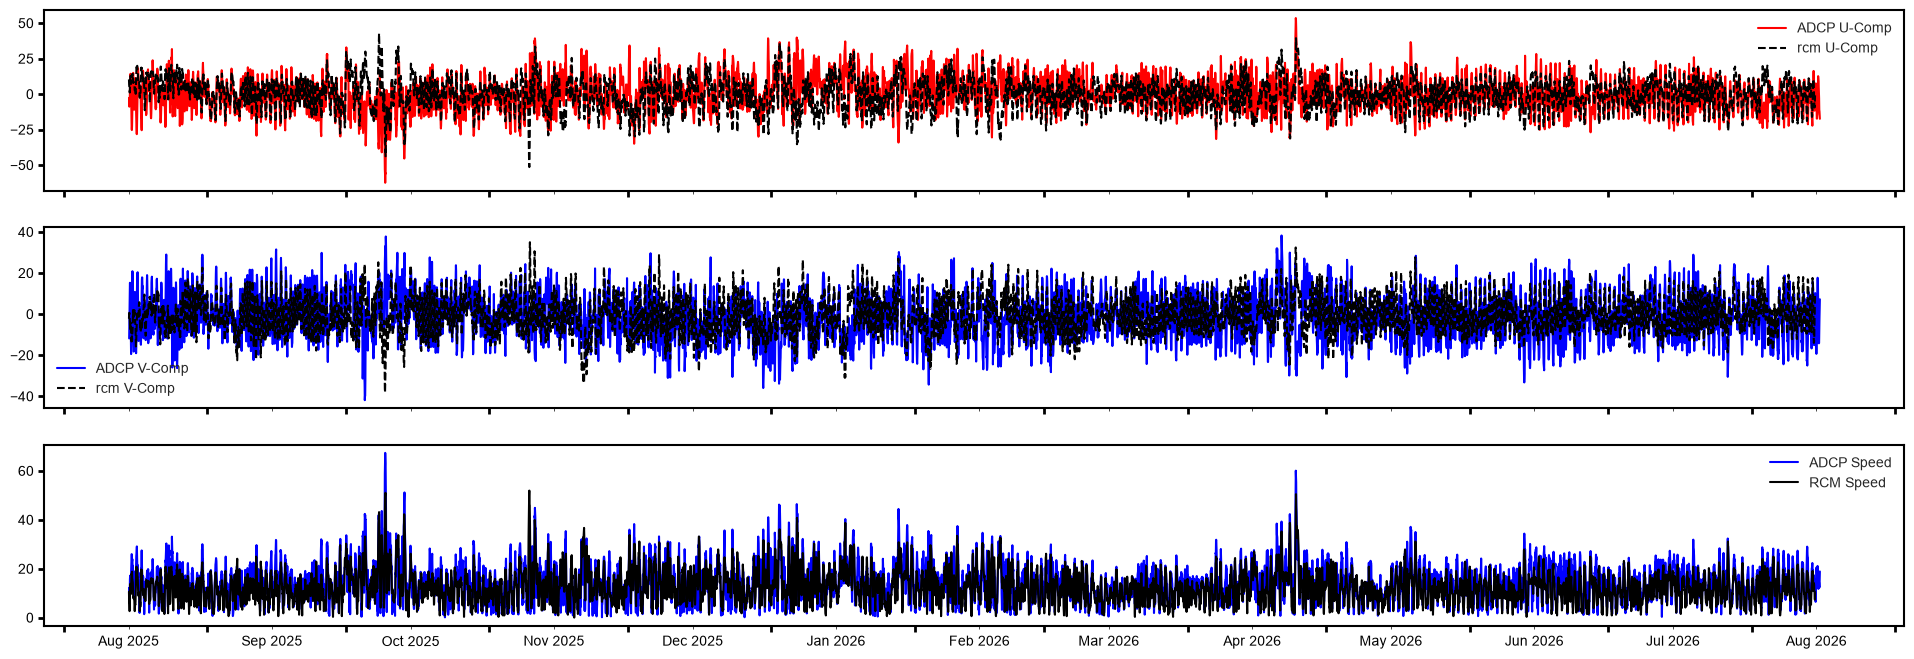

In [14]:
#wrap the plot in image settings for visual appeal
# may be able to make this cleaner or just a preset
# copy is in the notebook examples
%run '../../../settings/mpl_plot_settings.py'

%matplotlib inline
import matplotlib.dates as mdates
from matplotlib.dates import YearLocator, WeekdayLocator, MonthLocator, DayLocator, HourLocator, DateFormatter
import matplotlib.ticker as ticker


fig, ax = plt.subplots(3,figsize=(24, 8),sharex=True)
ax[0].plot(adcp_rcm_depth.index,adcp_rcm_depth.u_curr_comp,color='r',label='ADCP U-Comp')
ax[1].plot(adcp_rcm_depth.index,adcp_rcm_depth.v_curr_comp,color='b',label='ADCP V-Comp')
ax[2].plot(adcp_rcm_depth.index,
           np.sqrt(adcp_rcm_depth.v_curr_comp**2 + adcp_rcm_depth.u_curr_comp**2),
           color='b',label='ADCP Speed')
ax[0].plot(rcm_data.index,rcm_data.u_comp_current,'k--',label='rcm U-Comp')
ax[1].plot(rcm_data.index,rcm_data.v_comp_current,'k--',label='rcm V-Comp')
ax[2].plot(rcm_data.index,
           np.sqrt(rcm_data.v_comp_current**2 + rcm_data.u_comp_current**2),
           color='k',label='RCM Speed')
ax[0].legend()
ax[1].legend()
ax[2].legend()

xfmt = mdates.DateFormatter('%d-%b')
ax[2].xaxis.set_major_locator(DayLocator(bymonthday=1))
ax[2].xaxis.set_minor_locator(DayLocator(bymonthday=15))
ax[2].xaxis.set_minor_formatter(DateFormatter('%b %Y'))
ax[2].xaxis.set_major_formatter(DateFormatter(''))
ax[2].xaxis.set_tick_params(which='major', pad=3)
ax[2].xaxis.set_tick_params(which='minor', pad=5)

In [15]:
from typing import Tuple

def calculate_ts_correlation(
    ts1: pd.Series, 
    ts2: pd.Series, 
    method: str = "pearson"
) -> float:
    """
    Calculates correlation after ensuring time alignment.
    
    Args:
        ts1, ts2: Pandas Series with DatetimeIndex.
        method: Correlation type ('pearson', 'spearman').
    """
    # Alignment: Join on index to ensure we compare the same timestamps
    df = pd.concat([ts1, ts2], axis=1).dropna()
    
    if df.empty:
        raise ValueError("No overlapping time steps found between series.")
        
    return df.corr(method=method).iloc[0, 1]

In [20]:
print(f"U-comp correlation: {calculate_ts_correlation(adcp_rcm_depth.u_curr_comp,rcm_data.u_comp_current,'pearson')}")
print(f"V-comp correlation: {calculate_ts_correlation(adcp_rcm_depth.v_curr_comp,rcm_data.v_comp_current,'pearson')}")
print(f"Speed correlation: {calculate_ts_correlation(np.sqrt(adcp_rcm_depth.v_curr_comp**2 + adcp_rcm_depth.u_curr_comp**2),
                                                      np.sqrt(rcm_data.v_comp_current**2 + rcm_data.u_comp_current**2),'pearson')}")


U-comp correlation: 0.24127307946344526
V-comp correlation: 0.301849713415179
Speed correlation: 0.7698286457378478


/var/folders/6r/n_mpcj7d7pdf9ncqvjy5vb8c0000jm/T/ipykernel_39580/3331122382.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = pd.concat([ts1, ts2], axis=1).dropna()
/var/folders/6r/n_mpcj7d7pdf9ncqvjy5vb8c0000jm/T/ipykernel_39580/3331122382.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = pd.concat([ts1, ts2], axis=1).dropna()
/var/folders/6r/n_mpcj7d7pdf9ncqvjy5vb8c0000jm/T/ipykernel_39580/3331122382.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeI